<a href="https://colab.research.google.com/github/eugenestumme-ai/aim350-course-recommender/blob/main/aim350_course_recommender.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

# ==========================================
# 1. SIMULATED SURVEY DATASET (36 Respondents)
# (Replace with pd.read_csv('your_survey.csv') if using live CSV)
# Likert Scale (1-5) + Categorical Schedule Preference
# ==========================================
np.random.seed(42)

# Generating 3 clear behavioral/skill patterns across 36 students
group_1 = np.random.normal(loc=[1.8, 2.0, 2.2, 2.0], scale=0.4, size=(12, 4)) # Beginners / Structured learners
group_2 = np.random.normal(loc=[3.4, 3.6, 3.8, 3.5], scale=0.4, size=(12, 4)) # Intermediate / Visual & Collaborative
group_3 = np.random.normal(loc=[4.6, 4.5, 4.4, 4.6], scale=0.3, size=(12, 4)) # Advanced / Self-paced Quant

raw_numeric = np.clip(np.vstack([group_1, group_2, group_3]), 1, 5).round(1)
schedules = ['Morning/Structured']*12 + ['Afternoon/Collaborative']*12 + ['Evening/Self-Paced']*12

df_survey = pd.DataFrame(raw_numeric, columns=[
    'Spreadsheet_Skill_Level',     # 1-5 Likert
    'Data_Viz_Interest',           # 1-5 Likert
    'Quantitative_Comfort',        # 1-5 Likert
    'Study_Consistency_Hours'      # 1-5 Likert
])
df_survey['Preferred_Study_Block'] = schedules

# ==========================================
# 2. SLIDE 4: COLUMNTRANSFORMER & PREPROCESSING PIPELINE
# ==========================================
numeric_features = ['Spreadsheet_Skill_Level', 'Data_Viz_Interest', 'Quantitative_Comfort', 'Study_Consistency_Hours']
categorical_features = ['Preferred_Study_Block']
schedule_categories = [['Morning/Structured', 'Afternoon/Collaborative', 'Evening/Self-Paced']]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OrdinalEncoder(categories=schedule_categories), categorical_features)
    ]
)

# Full transformation pipeline with PCA (2 components for 2D verification)
feature_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('pca', PCA(n_components=2, random_state=42))
])

X_pca = feature_pipeline.fit_transform(df_survey)

# ==========================================
# 3. SLIDE 4: K-MEANS vs. HIERARCHICAL CLUSTERING (WARD'S LINKAGE)
# ==========================================
k_optimal = 3

# Model A: Partition-Based K-Means
kmeans_model = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_pca)

# Model B: Connectivity-Based Agglomerative Hierarchical (Ward's Linkage)
hier_model = AgglomerativeClustering(n_clusters=k_optimal, metric='euclidean', linkage='ward')
hier_labels = hier_model.fit_predict(X_pca)

# Quantitative Validation Metrics (Target: Silhouette > 0.40, Low Davies-Bouldin)
km_sil = silhouette_score(X_pca, kmeans_labels)
km_dbi = davies_bouldin_score(X_pca, kmeans_labels)
hc_sil = silhouette_score(X_pca, hier_labels)
hc_dbi = davies_bouldin_score(X_pca, hier_labels)

metrics_df = pd.DataFrame({
    'Clustering Algorithm': ['K-Means (Partition-Based)', 'Agglomerative Hierarchical (Ward Linkage)'],
    'Silhouette Score (Goal > 0.40)': [round(km_sil, 3), round(hc_sil, 3)],
    'Davies-Bouldin Index (Lower = Better)': [round(km_dbi, 3), round(hc_dbi, 3)]
})
print("=== SLIDE 4: CLUSTERING EVALUATION METRICS ===")
display(metrics_df)

# ==========================================
# 4. SLIDE 5: STRUCTURED RECOMMENDATION DICTIONARY & .predict() ENGINE
# ==========================================
# Identify cluster order by sorting centroids from Beginner -> Intermediate -> Advanced
centroid_means = kmeans_model.cluster_centers_.sum(axis=1)
sorted_cluster_ids = np.argsort(centroid_means)

recommendation_dictionary = {
    sorted_cluster_ids[0]: {
        "Profile_Name": "Foundational Structured Learner",
        "Recommended_Courses": "Microsoft Excel (Beginner Track) -> Intro to Intermediate Excel",
        "Study_Strategy": "Guided step-by-step lab worksheets, morning structured blocks, and foundational formula drills."
    },
    sorted_cluster_ids[1]: {
        "Profile_Name": "Applied Visual & BI Analyst",
        "Recommended_Courses": "Microsoft Excel (Intermediate) & Tableau Visual Analytics",
        "Study_Strategy": "Peer-group dashboard critiques, afternoon collaborative study sessions, and interactive case studies."
    },
    sorted_cluster_ids[2]: {
        "Profile_Name": "Advanced Data Modeling & BI Architect",
        "Recommended_Courses": "Microsoft Excel (Advanced Macros/PowerQuery) & Microsoft Power BI",
        "Study_Strategy": "Self-paced evening capstone projects, relational data modeling challenges, and DAX query practice."
    }
}

def predict_student_recommendation(new_student_dict, student_label="New Student"):
    """
    Live Demo Inference Function:
    1. Converts unseen respondent inputs into a DataFrame
    2. Passes through fitted ColumnTransformer + PCA Pipeline
    3. Uses .predict() on K-Means to assign cluster centroid membership
    4. Outputs tailored Excel / Power BI / Tableau course & study strategy
    """
    new_df = pd.DataFrame([new_student_dict])

    # Transform unseen user inputs using fitted pipeline (prevents data leakage)
    new_pca_coords = feature_pipeline.transform(new_df)

    # Predict cluster membership via centroids
    assigned_cluster = kmeans_model.predict(new_pca_coords)[0]
    rec = recommendation_dictionary[assigned_cluster]

    print(f"\n=========================================")
    print(f" LIVE INFERENCE OUTPUT FOR: {student_label}")
    print(f"=========================================")
    print(f"Assigned Cluster ID : Cluster {assigned_cluster} ({rec['Profile_Name']})")
    print(f"Course Placement    : {rec['Recommended_Courses']}")
    print(f"Study Strategy      : {rec['Study_Strategy']}")

    # Plot 2D PCA Clusters + Highlight Unseen Student
    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        x=X_pca[:, 0], y=X_pca[:, 1],
        hue=[recommendation_dictionary[c]['Profile_Name'] for c in kmeans_labels],
        palette='viridis', s=90, alpha=0.8
    )
    # Plot Centroids
    plt.scatter(
        kmeans_model.cluster_centers_[:, 0], kmeans_model.cluster_centers_[:, 1],
        c='red', marker='X', s=200, label='Cluster Centroids'
    )
    # Plot Unseen Test Student
    plt.scatter(
        new_pca_coords[0, 0], new_pca_coords[0, 1],
        c='gold', edgecolors='black', marker='*', s=450, label=f'Unseen Input: {student_label}'
    )
    plt.title(f"2D PCA Cluster Projection & Live .predict() Mapping ({student_label})")
    plt.xlabel("Principal Component 1 (Skill & Quantitative Readiness)")
    plt.ylabel("Principal Component 2 (Study Habit & Schedule Preference)")
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

=== SLIDE 4: CLUSTERING EVALUATION METRICS ===


,Clustering Algorithm,Silhouette Score (Goal > 0.40),Davies-Bouldin Index (Lower = Better)
0,K-Means (Partition-Based),0.737,0.371
1,Agglomerative Hierarchical (Ward Linkage),0.737,0.371



 LIVE INFERENCE OUTPUT FOR: Student A (Foundational Input)
Assigned Cluster ID : Cluster 1 (Foundational Structured Learner)
Course Placement    : Microsoft Excel (Beginner Track) -> Intro to Intermediate Excel
Study Strategy      : Guided step-by-step lab worksheets, morning structured blocks, and foundational formula drills.


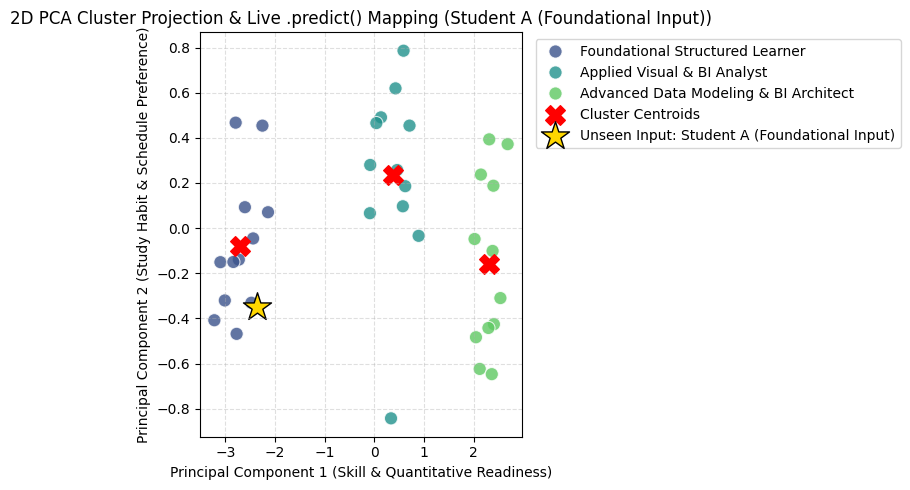


 LIVE INFERENCE OUTPUT FOR: Student B (Advanced Input)
Assigned Cluster ID : Cluster 0 (Advanced Data Modeling & BI Architect)
Course Placement    : Microsoft Excel (Advanced Macros/PowerQuery) & Microsoft Power BI
Study Strategy      : Self-paced evening capstone projects, relational data modeling challenges, and DAX query practice.


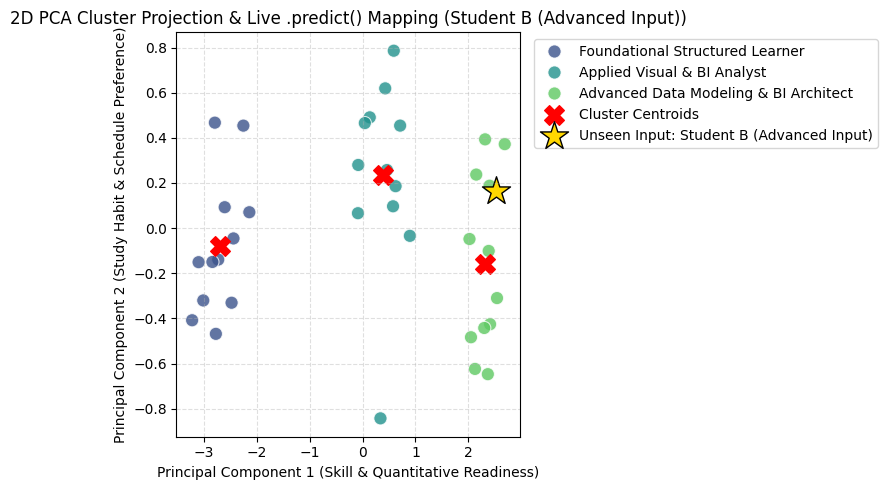

In [ ]:
# TEST CASE A: Student needing foundational skills & structured guidance
student_A = {
    'Spreadsheet_Skill_Level': 2.0,
    'Data_Viz_Interest': 2.0,
    'Quantitative_Comfort': 2.0,
    'Study_Consistency_Hours': 2.5,
    'Preferred_Study_Block': 'Morning/Structured'
}
predict_student_recommendation(student_A, student_label="Student A (Foundational Input)")

# TEST CASE B: Student ready for advanced modeling & evening self-paced work
student_B = {
    'Spreadsheet_Skill_Level': 4.8,
    'Data_Viz_Interest': 4.5,
    'Quantitative_Comfort': 4.7,
    'Study_Consistency_Hours': 4.5,
    'Preferred_Study_Block': 'Evening/Self-Paced'
}
predict_student_recommendation(student_B, student_label="Student B (Advanced Input)")